# HAM10000 Skin Lesion Classification
## Tabular-only vs. Image-only (custom CNN from scratch) vs. Multimodal

---

## 1. Project introduction and objectives

**Dataset.** HAM10000 ("Human Against Machine with 10000 training images") contains dermatoscopic images of pigmented skin lesions together with a metadata table (`age`, `sex`, `localization`, `lesion_id`, ...). Each image is labelled with one of **7 diagnostic classes** (column `dx`):

| Code | Diagnosis |
|---|---|
| `akiec` | Actinic keratoses / intraepithelial carcinoma |
| `bcc` | Basal cell carcinoma |
| `bkl` | Benign keratosis-like lesions |
| `df` | Dermatofibroma |
| `mel` | Melanoma |
| `nv` | Melanocytic nevi |
| `vasc` | Vascular lesions |

**Goal.** Compare three ways of predicting `dx` **fairly**:

1. **Tabular-only**: Random Forest and XGBoost using `age`, `sex`, `localization`.
2. **Image-only**: a **custom CNN built completely from scratch** (no pretrained weights, no MobileNet/ResNet/EfficientNet).
3. **Multimodal**: image features from a custom from-scratch CNN **+** the tabular features, fused in one network.

**Fair-comparison protocol** (what makes the comparison trustworthy):

| Rule | How it is enforced |
|---|---|
| Same data split for every model | One **lesion-grouped** train/validation/test split (`lesion_id` groups, so the same lesion never appears in two splits) |
| No test-set leakage | The test set is created and used **only in Section 10**. Training, early stopping, learning-rate scheduling, checkpoint choice and the Random-Forest-vs-XGBoost choice all use the **validation** set only |
| Same imbalance strategy | The same "balanced" class weights, computed from the training labels, are used by every model |
| Same selection metric | Models are selected on validation **macro-F1** (the metric that matters under class imbalance) |
| Same metrics everywhere | Accuracy, Macro-F1, Weighted-F1, classification report, confusion matrix |
| Nothing hardcoded | Every number in the final tables and plots is computed by running the notebook |

**How to run (Google Colab)**

1. `Runtime → Change runtime type → T4 GPU`.
2. `Runtime → Run all`.
3. Two interactive steps will appear: *(a)* Google Drive authorisation (optional, can be switched off in Section 2), *(b)* upload of your `kaggle.json` (Section 3). Get it from Kaggle: *Account → Settings → API → Create New Token*.
4. To check that everything runs in a couple of minutes, set `QUICK_TEST = True` in Section 2 (the networks then train for only 2 epochs; **the results are then meaningless**, it is only a smoke test).

> **Disclaimer.** This is an educational project. The models are not clinically validated and must not be used for medical diagnosis.

**Contents**

1. Project introduction and objectives
2. Imports and environment setup
3. Dataset loading and image-path matching
4. Exploratory data analysis and class distribution
5. Missing values and preprocessing
6. Train/validation/test split using `lesion_id` grouping
7. Tabular-only experiments (Random Forest, XGBoost)
8. Image-only experiment (custom CNN from scratch)
9. Multimodal experiment (custom CNN + tabular features)
10. Final evaluation and comparison of all three approaches
11. Conclusions and limitations

---
## 2. Imports and environment setup

### 2.1 Install and import libraries
Colab already includes TensorFlow, scikit-learn, pandas, matplotlib, seaborn, Pillow and tqdm. We only make sure **XGBoost** and the **Kaggle CLI** are installed.

In [ ]:
# Colab already ships with most libraries; this makes sure XGBoost and the Kaggle CLI exist.
!pip -q install xgboost kaggle

In [ ]:
import os
import json
import time
import warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import joblib
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# google.colab only exists inside Colab; the notebook also runs elsewhere if the dataset is already on disk.
try:
    from google.colab import files, drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid")
print("Libraries imported. Running in Colab:", IN_COLAB)

Libraries imported. Running in Colab: True


### 2.2 Global settings
All important switches are in this one cell. Every later section reads these values, so no result depends on variables left over from an earlier Colab session.

In [ ]:
# ======================== GLOBAL SETTINGS (edit here) ========================
SEED = 42                 # one seed everywhere: reproducible split, initialisation and shuffling
IMG_SIZE = 128            # every image is resized to IMG_SIZE x IMG_SIZE (same for ALL image models)
BATCH_SIZE = 32
QUICK_TEST = False        # True = only 2 epochs per network (smoke test, results are NOT meaningful)
MAX_EPOCHS = 2 if QUICK_TEST else 60
N_BOOTSTRAP = 50 if QUICK_TEST else 500
USE_GOOGLE_DRIVE = True   # True: store outputs on Google Drive so they survive a runtime reset
FORCE_RETRAIN = True      # False: if a saved best_model.keras exists, load it instead of retraining
# =============================================================================

keras.utils.set_random_seed(SEED)   # seeds Python, NumPy and TensorFlow together

print("TensorFlow version:", tf.__version__)
available_gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", available_gpus if available_gpus else "none")
if not available_gpus:
    print("WARNING: no GPU found. CNN training will be very slow. "
          "Use Runtime > Change runtime type > T4 GPU.")

TensorFlow version: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 2.3 Google Drive (optional) and output folders
If `USE_GOOGLE_DRIVE = True`, Colab asks you to authorise access to your Drive. Models, training histories, configurations, figures and result tables are then saved in `MyDrive/HAM10000_project/`. If mounting fails (or you decline), the notebook automatically falls back to local storage (`/content/HAM10000_project`, which is deleted when the runtime resets).

The large dataset itself (about 5 GB) is always stored on the fast local disk `/content`, never on Drive.

In [ ]:
PROJECT_DIR = Path("/content/HAM10000_project")      # fallback: local storage

if USE_GOOGLE_DRIVE and IN_COLAB:
    try:
        drive.mount("/content/drive")
        PROJECT_DIR = Path("/content/drive/MyDrive/HAM10000_project")
    except Exception as error:
        print(f"Could not mount Google Drive ({error}). Using local storage instead.")

DATA_DIR = Path("/content/ham10000_data")            # dataset (local disk)
CACHE_DIR = Path("/content/cache")                   # resized-image cache (local disk)
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"
TABULAR_DIR = PROJECT_DIR / "tabular_models"
CNN_DIR = PROJECT_DIR / "cnn_scratch"                # experiment folder: image-only CNN
MULTIMODAL_DIR = PROJECT_DIR / "multimodal_scratch"  # experiment folder: multimodal model

for folder in [DATA_DIR, CACHE_DIR, FIGURES_DIR, RESULTS_DIR, TABULAR_DIR, CNN_DIR, MULTIMODAL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Outputs will be saved in:", PROJECT_DIR)

Mounted at /content/drive
Outputs will be saved in: /content/drive/MyDrive/HAM10000_project


### 2.4 Helper functions for evaluation
These small functions are used for **every** model so that all approaches are evaluated in exactly the same way: accuracy, macro-F1, weighted-F1, a full classification report and a confusion matrix (raw counts on the left, row-normalised on the right, where the diagonal is the per-class recall).

In [ ]:
def compute_metrics(y_true, y_pred):
    # The three metrics used in the final comparison.
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    labels = np.arange(len(class_names))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_normalised = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set(title=f"{title}: counts", xlabel="Predicted class", ylabel="True class")
    sns.heatmap(cm_normalised, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set(title=f"{title}: share of each true class", xlabel="Predicted class", ylabel="True class")
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def report_predictions(model_name, split_name, y_true, y_pred, class_names=None, save_path=None):
    # Prints metrics + classification report, draws the confusion matrix, returns the metrics dict.
    class_names = class_names or CLASS_NAMES
    metrics = compute_metrics(y_true, y_pred)
    print(f"{model_name}  |  {split_name} set")
    print("-" * 60)
    print(f"Accuracy    : {metrics['accuracy']:.4f}")
    print(f"Macro F1    : {metrics['macro_f1']:.4f}")
    print(f"Weighted F1 : {metrics['weighted_f1']:.4f}\n")
    print(classification_report(y_true, y_pred, labels=np.arange(len(class_names)),
                                target_names=class_names, zero_division=0, digits=3))
    plot_confusion_matrix(y_true, y_pred, class_names, f"{model_name} ({split_name})", save_path)
    return metrics

---
## 3. Dataset loading and image-path matching

### 3.1 Download HAM10000 from Kaggle
The dataset is `kmader/skin-cancer-mnist-ham10000` (about 5 GB, the download takes a few minutes).

**What you need to do:** when the cell below asks, click *Choose files* and upload your **`kaggle.json`** (Kaggle → Account → Settings → API → *Create New Token*). Colab runtimes are temporary, so you must upload it again after every runtime reset.

If the dataset is already on disk (for example because you re-run the notebook in the same session), the download is skipped automatically.

In [ ]:
METADATA_FILE = "HAM10000_metadata.csv"


def find_metadata_file():
    matches = list(DATA_DIR.rglob(METADATA_FILE))
    return matches[0] if matches else None


def ensure_kaggle_credentials():
    kaggle_json = Path.home() / ".kaggle" / "kaggle.json"
    if kaggle_json.exists() or ("KAGGLE_USERNAME" in os.environ and "KAGGLE_KEY" in os.environ):
        print("Kaggle credentials found.")
        return
    if not IN_COLAB:
        raise FileNotFoundError("Put kaggle.json in ~/.kaggle/ or set KAGGLE_USERNAME and KAGGLE_KEY.")
    print("Please upload your kaggle.json file:")
    uploaded = files.upload()
    # Colab may rename repeated uploads, e.g. 'kaggle (4).json', so search by pattern.
    candidates = [name for name in uploaded if "kaggle" in name.lower() and name.lower().endswith(".json")]
    if not candidates:
        raise FileNotFoundError("No kaggle.json was uploaded. Run this cell again and upload the file.")
    kaggle_json.parent.mkdir(parents=True, exist_ok=True)
    kaggle_json.write_bytes(uploaded[candidates[0]])
    os.chmod(kaggle_json, 0o600)
    print("Kaggle credentials saved.")


if find_metadata_file() is None:
    ensure_kaggle_credentials()
    print("Downloading HAM10000 (about 5 GB). This can take several minutes...")
    !kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p {DATA_DIR} --unzip
else:
    print("Dataset already present, skipping download.")

assert find_metadata_file() is not None, "Download failed: HAM10000_metadata.csv not found."
print("Metadata file:", find_metadata_file())

Please upload your kaggle.json file:


Saving kaggle(1).json to kaggle(1).json
Kaggle credentials saved.
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:31<00:00, 177MB/s]

Metadata file: /content/ham10000_data/HAM10000_metadata.csv


### 3.2 Load the metadata and match every row to its image file
Image file names (`ISIC_xxxxxxx.jpg`) are matched to the `image_id` column. We search all `.jpg` files recursively, so it does not matter how the dataset folders are organised. The class labels in `dx` are **not modified**.

In [ ]:
df = pd.read_csv(find_metadata_file())

# Map every image_id to its file path (search all jpgs recursively).
image_path_by_id = {path.stem: str(path) for path in DATA_DIR.rglob("*.jpg")}
df["image_path"] = df["image_id"].map(image_path_by_id)

n_missing_paths = int(df["image_path"].isna().sum())
assert n_missing_paths == 0, f"{n_missing_paths} metadata rows have no image file."
assert df["image_id"].is_unique, "image_id should be unique."

df = df.reset_index(drop=True)   # row position == index (the split below relies on this)

# Class list (sorted) and the fixed class <-> integer mapping used by EVERY model.
CLASS_NAMES = sorted(df["dx"].unique())
NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
LESION_NAMES = {   # only used to make plots readable; the dataset labels stay the original codes
    "akiec": "Actinic keratoses", "bcc": "Basal cell carcinoma", "bkl": "Benign keratosis",
    "df": "Dermatofibroma", "mel": "Melanoma", "nv": "Melanocytic nevi", "vasc": "Vascular lesions",
}

print("Dataset shape :", df.shape)
print("Columns       :", df.columns.tolist())
print("Images matched:", df["image_path"].notna().sum(), "of", len(df))
print("Classes       :", CLASS_NAMES)
print("Original image size (example):", Image.open(df.loc[0, "image_path"]).size, "(width x height)")
display(df.head())

Dataset shape : (10015, 8)
Columns       : ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'image_path']
Images matched: 10015 of 10015
Classes       : ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Original image size (example): (600, 450) (width x height)


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,/content/ham10000_data/ham10000_images_part_1/...
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,/content/ham10000_data/ham10000_images_part_1/...
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,/content/ham10000_data/ham10000_images_part_1/...
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,/content/ham10000_data/ham10000_images_part_1/...
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,/content/ham10000_data/HAM10000_images_part_2/...


---
## 4. Exploratory data analysis and class distribution

### 4.1 Class distribution
HAM10000 is **strongly imbalanced**: one class (melanocytic nevi, `nv`) dominates. This is why plain accuracy is misleading and why we report **macro-F1** (which gives every class the same weight) and use class weights during training.

,Diagnosis,Images,Percentage
akiec,Actinic keratoses,327,3.27
bcc,Basal cell carcinoma,514,5.13
bkl,Benign keratosis,1099,10.97
df,Dermatofibroma,115,1.15
mel,Melanoma,1113,11.11
nv,Melanocytic nevi,6705,66.95
vasc,Vascular lesions,142,1.42


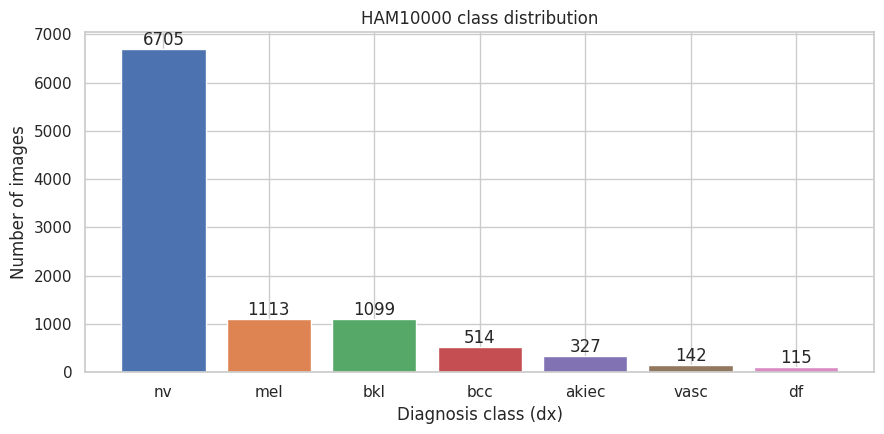

In [ ]:
class_counts = df["dx"].value_counts().reindex(CLASS_NAMES)
class_table = pd.DataFrame({
    "Diagnosis": [LESION_NAMES[c] for c in CLASS_NAMES],
    "Images": class_counts.values,
    "Percentage": (class_counts / len(df) * 100).round(2).values,
}, index=CLASS_NAMES)
display(class_table)

order = class_counts.sort_values(ascending=False).index.tolist()
plt.figure(figsize=(9, 4.5))
plt.bar(order, class_counts[order].to_numpy(), color=sns.color_palette("deep", NUM_CLASSES))
for position, cls in enumerate(order):
    plt.text(position, class_counts[cls], str(class_counts[cls]), ha="center", va="bottom")
plt.title("HAM10000 class distribution")
plt.xlabel("Diagnosis class (dx)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150)
plt.show()

### 4.2 Metadata distributions (age, sex, localization)

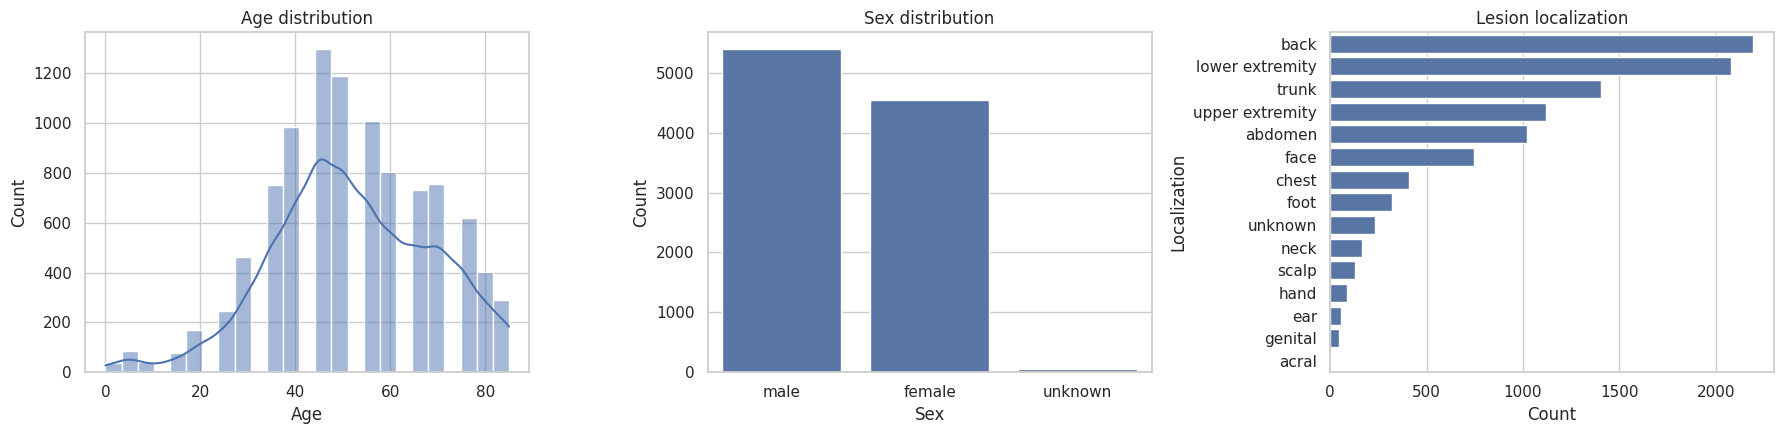

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

sns.histplot(data=df, x="age", bins=25, kde=True, ax=axes[0])
axes[0].set(title="Age distribution", xlabel="Age", ylabel="Count")

sns.countplot(data=df, x="sex", ax=axes[1])
axes[1].set(title="Sex distribution", xlabel="Sex", ylabel="Count")

sns.countplot(data=df, y="localization", order=df["localization"].value_counts().index, ax=axes[2])
axes[2].set(title="Lesion localization", xlabel="Count", ylabel="Localization")

plt.tight_layout()
plt.show()

### 4.3 Example images of each class

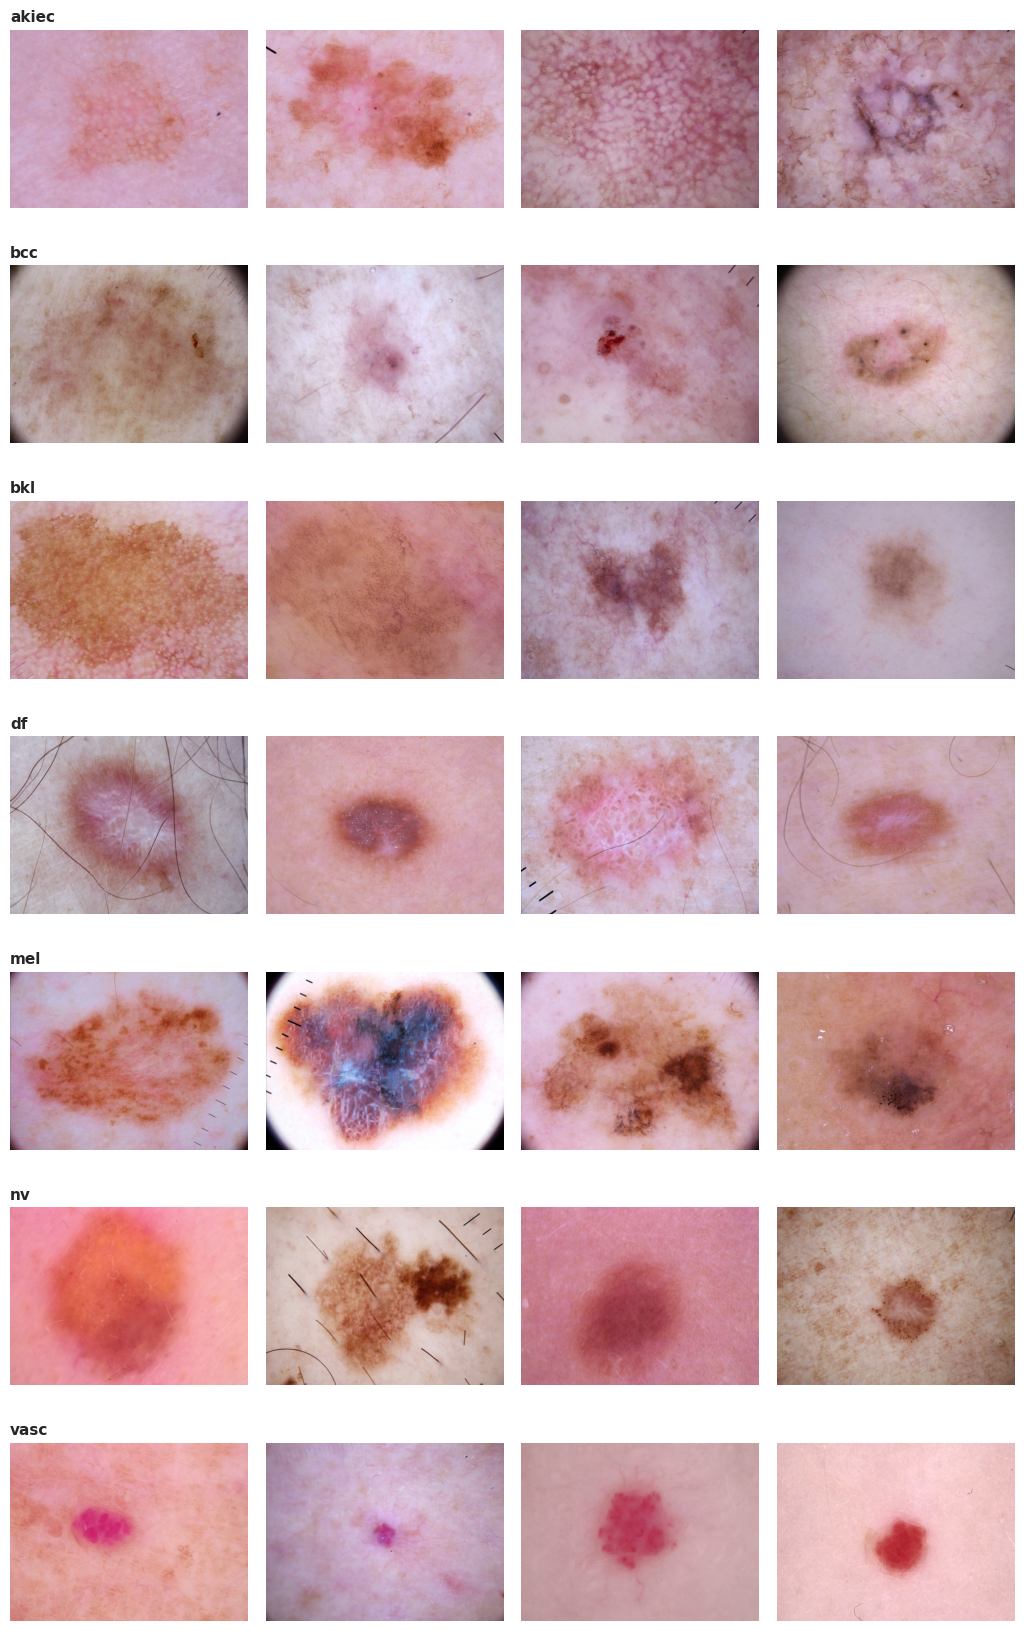

In [ ]:
images_per_class = 4
fig, axes = plt.subplots(NUM_CLASSES, images_per_class, figsize=(2.6 * images_per_class, 2.4 * NUM_CLASSES))
for row_idx, class_name in enumerate(CLASS_NAMES):
    examples = df[df["dx"] == class_name].sample(images_per_class, random_state=SEED)
    for col_idx, (_, record) in enumerate(examples.iterrows()):
        ax = axes[row_idx, col_idx]
        ax.imshow(Image.open(record["image_path"]).convert("RGB"))
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(f"{class_name}", loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.4 Why we must split by lesion
Several images can show **the same lesion** (photographed from different angles or at different times). If such near-duplicates ended up in both the training and the test set, the model would be rewarded for memorising a lesion rather than learning to generalise. That is data leakage, so the split in Section 6 is grouped by `lesion_id`.

In [ ]:
images_per_lesion = df.groupby("lesion_id")["image_id"].nunique()
print("Unique lesions                  :", len(images_per_lesion))
print("Lesions with more than 1 image  :", int((images_per_lesion > 1).sum()),
      f"({(images_per_lesion > 1).mean() * 100:.1f}% of lesions)")
print("Maximum images of a single lesion:", int(images_per_lesion.max()))

Unique lesions                  : 7470
Lesions with more than 1 image  : 1956 (26.2% of lesions)
Maximum images of a single lesion: 6


---
## 5. Missing values and preprocessing

### 5.1 Missing values in the tabular features

In [ ]:
TABULAR_FEATURES = ["age", "sex", "localization"]
NUMERIC_FEATURES = ["age"]
CATEGORICAL_FEATURES = ["sex", "localization"]

missing_table = df[TABULAR_FEATURES].isna().sum().to_frame("missing values")
missing_table["% of rows"] = (missing_table["missing values"] / len(df) * 100).round(2)
display(missing_table)

print("sex values         :", sorted(df["sex"].dropna().unique()))
print("localization values:", sorted(df["localization"].dropna().unique()))

,missing values,% of rows
age,57,0.57
sex,0,0.00
localization,0,0.00


sex values         : ['female', 'male', 'unknown']
localization values: ['abdomen', 'acral', 'back', 'chest', 'ear', 'face', 'foot', 'genital', 'hand', 'lower extremity', 'neck', 'scalp', 'trunk', 'unknown', 'upper extremity']


### 5.2 Preprocessing pipeline (defined now, fitted later on the training set only)
Only `age` has missing values. We use **one shared preprocessing object for all models** so that the tabular, image and multimodal experiments see exactly the same tabular input:

| Feature | Processing |
|---|---|
| `age` (numeric) | missing values → **median of the training set**, then standardised (mean 0, std 1; helps the neural network, harmless for trees) |
| `sex`, `localization` (categorical) | most-frequent imputation (safety net), then **one-hot encoding**. The dataset's `"unknown"` values are kept as their own category |

> **Important:** the pipeline is only *defined* here. It is *fitted on the training split only* in Section 6 (medians, means and categories come from training data), then applied to validation and test data. Fitting it on the full dataset would leak information from the test set.

We also add an integer label column `label` (class index) next to the original `dx` column. `dx` itself is untouched.

In [ ]:
df["label"] = df["dx"].map(CLASS_TO_IDX).astype(int)

tabular_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), NUMERIC_FEATURES),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
         CATEGORICAL_FEATURES),
    ],
    sparse_threshold=0.0,   # always return a dense array
)
print("Class -> integer mapping:", CLASS_TO_IDX)

Class -> integer mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


---
## 6. Train / validation / test split using `lesion_id` grouping

### 6.1 The split (kept from the original notebook)
`StratifiedGroupKFold` keeps **all images of one lesion together** (`groups=lesion_id`) while keeping the class proportions similar in every part (`stratified`).

* First split: about **80 %** train+validation and **20 %** test.
* Second split (inside the 80 %): about 80 % train / 20 % validation, so overall roughly **64 % / 16 % / 20 %**.

| Set | Used for |
|---|---|
| Train | fitting the models (and fitting the preprocessing) |
| Validation | early stopping, learning-rate scheduling, checkpoint choice, choosing between Random Forest and XGBoost |
| Test | **only** the final evaluation in Section 10 |

In [ ]:
# First split: ~80% train+validation, ~20% test (grouped by lesion)
outer_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_val_idx, test_idx = next(outer_splitter.split(np.zeros(len(df)), df["dx"], groups=df["lesion_id"]))

# Second split: ~80% train, ~20% validation (grouped by lesion, inside train+validation)
inner_splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_local_idx, val_local_idx = next(inner_splitter.split(
    np.zeros(len(train_val_idx)),
    df.iloc[train_val_idx]["dx"],
    groups=df.iloc[train_val_idx]["lesion_id"],
))

train_idx = train_val_idx[train_local_idx]
val_idx = train_val_idx[val_local_idx]

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()    # NOT used again until Section 10

print(f"Train: {len(train_df)} ({len(train_df) / len(df):.1%})")
print(f"Val  : {len(val_df)} ({len(val_df) / len(df):.1%})")
print(f"Test : {len(test_df)} ({len(test_df) / len(df):.1%})")

Train: 6409 (64.0%)
Val  : 1592 (15.9%)
Test : 2014 (20.1%)


### 6.2 Check the split: class balance and leakage
The assertions below stop the notebook if any lesion appears in more than one split.

In [ ]:
split_counts = pd.DataFrame({
    "train": train_df["dx"].value_counts(),
    "validation": val_df["dx"].value_counts(),
    "test": test_df["dx"].value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)

print("Images per class and split:")
display(split_counts)
print("Class share inside each split (%):")
display((split_counts / split_counts.sum() * 100).round(2))

# Leakage checks: no lesion may appear in two splits.
train_lesions, val_lesions, test_lesions = (set(d["lesion_id"]) for d in (train_df, val_df, test_df))
print("Lesion overlap  train & val :", len(train_lesions & val_lesions))
print("Lesion overlap  train & test:", len(train_lesions & test_lesions))
print("Lesion overlap  val & test  :", len(val_lesions & test_lesions))
assert not (train_lesions & val_lesions), "Leakage between train and validation!"
assert not (train_lesions & test_lesions), "Leakage between train and test!"
assert not (val_lesions & test_lesions), "Leakage between validation and test!"
assert (split_counts["train"] > 0).all(), "A class is missing from the training set."

# Save the split so it can be reproduced and inspected later.
split_assignments = df[["image_id", "lesion_id", "dx"]].copy()
split_assignments["split"] = "train"
split_assignments.loc[val_idx, "split"] = "validation"
split_assignments.loc[test_idx, "split"] = "test"
split_assignments.to_csv(RESULTS_DIR / "split_assignments.csv", index=False)

Images per class and split:


,train,validation,test
dx,,,
akiec,208,51,68
bcc,343,71,100
bkl,730,164,205
df,79,14,22
mel,728,163,222
nv,4248,1094,1363
vasc,73,35,34


Class share inside each split (%):


,train,validation,test
dx,,,
akiec,3.25,3.20,3.38
bcc,5.35,4.46,4.97
bkl,11.39,10.30,10.18
df,1.23,0.88,1.09
mel,11.36,10.24,11.02
nv,66.28,68.72,67.68
vasc,1.14,2.20,1.69


Lesion overlap  train & val : 0
Lesion overlap  train & test: 0
Lesion overlap  val & test  : 0


### 6.3 Class imbalance: class weights
Rare classes (e.g. `df`, `vasc`) would be ignored by a model that simply predicts `nv` most of the time. We therefore weight each training sample by `n_samples / (n_classes * n_samples_of_its_class)` (scikit-learn's `"balanced"` rule): rare classes get a large weight, frequent classes a small one.

The weights are computed **from the training labels only** and are used by **all** models (Random Forest, XGBoost, CNN, multimodal), which keeps the comparison fair.

In [ ]:
y_train = df["label"].to_numpy()[train_idx]
y_val = df["label"].to_numpy()[val_idx]

class_weights_array = compute_class_weight(class_weight="balanced",
                                           classes=np.arange(NUM_CLASSES), y=y_train)
class_weight_by_idx = {idx: float(weight) for idx, weight in enumerate(class_weights_array)}
train_sample_weights = class_weights_array[y_train].astype("float32")   # one weight per training image

display(pd.DataFrame({"class": CLASS_NAMES,
                      "train images": np.bincount(y_train, minlength=NUM_CLASSES),
                      "weight": class_weights_array.round(3)}).set_index("class"))

,train images,weight
class,,
akiec,208,4.402
bcc,343,2.669
bkl,730,1.254
df,79,11.590
mel,728,1.258
nv,4248,0.216
vasc,73,12.542


### 6.4 Fit the tabular preprocessing on the training set only
From here on, the tabular features exist as numeric matrices: `X_tab_train` and `X_tab_val`. (The test matrix is created in Section 10.)

In [ ]:
X_tab_train = tabular_preprocessor.fit_transform(train_df[TABULAR_FEATURES]).astype("float32")  # fit on TRAIN only
X_tab_val = tabular_preprocessor.transform(val_df[TABULAR_FEATURES]).astype("float32")

tabular_feature_names = list(tabular_preprocessor.get_feature_names_out())
assert not np.isnan(X_tab_train).any() and not np.isnan(X_tab_val).any()

print("Tabular matrix shapes -> train:", X_tab_train.shape, "| validation:", X_tab_val.shape)
print("Features:", tabular_feature_names)

Tabular matrix shapes -> train: (6409, 19) | validation: (1592, 19)
Features: ['num__age', 'cat__sex_female', 'cat__sex_male', 'cat__sex_unknown', 'cat__localization_abdomen', 'cat__localization_acral', 'cat__localization_back', 'cat__localization_chest', 'cat__localization_ear', 'cat__localization_face', 'cat__localization_foot', 'cat__localization_genital', 'cat__localization_hand', 'cat__localization_lower extremity', 'cat__localization_neck', 'cat__localization_scalp', 'cat__localization_trunk', 'cat__localization_unknown', 'cat__localization_upper extremity']


---
## 7. Tabular-only experiments

Both tabular models use only `age`, `sex` and `localization`, the same class weights, and the same preprocessed matrices. The hyper-parameters are exactly the ones from your original experiments. They are evaluated on the **validation** set; each fitted model is saved with `joblib` so it can be re-loaded for the final test evaluation.

All validation results are collected in the dictionary `validation_results`.

### 7.1 Random Forest

Random Forest  |  validation set
------------------------------------------------------------
Accuracy    : 0.4353
Macro F1    : 0.2014
Weighted F1 : 0.5160

              precision    recall  f1-score   support

       akiec      0.101     0.275     0.147        51
         bcc      0.079     0.211     0.115        71
         bkl      0.219     0.183     0.199       164
          df      0.039     0.500     0.072        14
         mel      0.158     0.178     0.167       163
          nv      0.904     0.545     0.680      1094
        vasc      0.020     0.057     0.029        35

    accuracy                          0.435      1592
   macro avg      0.217     0.278     0.201      1592
weighted avg      0.668     0.435     0.516      1592



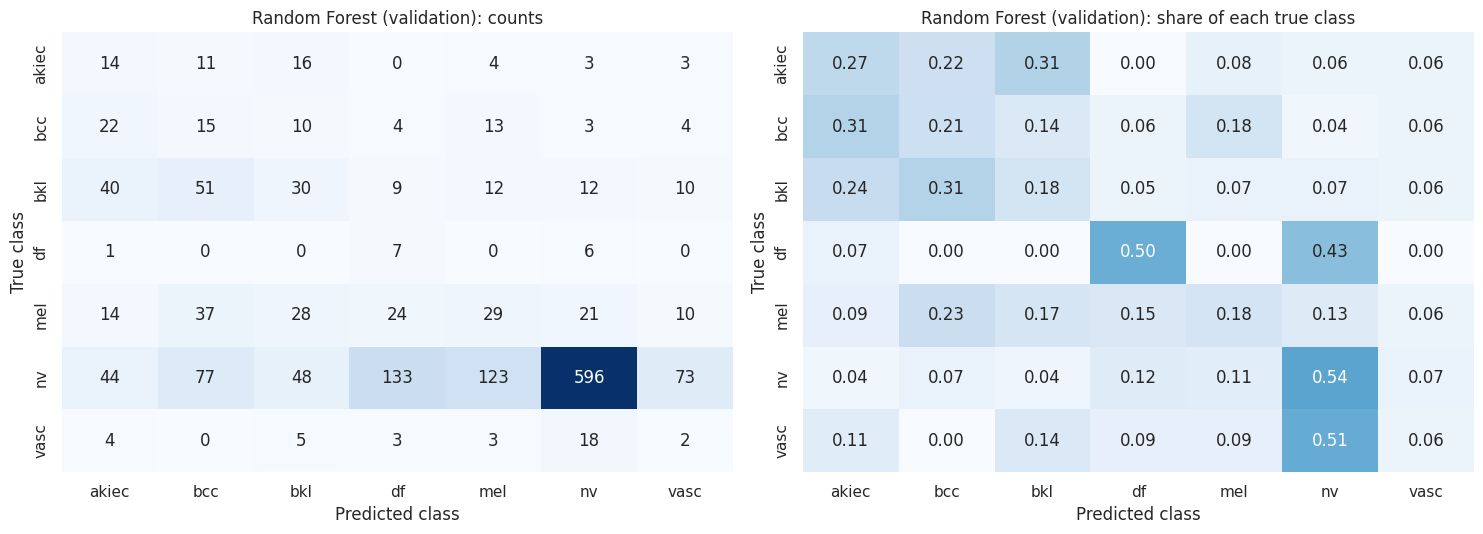

In [ ]:
validation_results = {}   # model name -> validation metrics (filled by every experiment)

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight=class_weight_by_idx,
    random_state=SEED,
    n_jobs=-1,
)
rf_model.fit(X_tab_train, y_train)
joblib.dump(rf_model, TABULAR_DIR / "random_forest.joblib", compress=3)

rf_val_pred = rf_model.predict(X_tab_val)
validation_results["Random Forest"] = report_predictions(
    "Random Forest", "validation", y_val, rf_val_pred,
    save_path=FIGURES_DIR / "confusion_matrix_val_random_forest.png")

### 7.2 XGBoost
XGBoost has no `class_weight` argument, so the same class weights are passed as per-sample weights.

XGBoost  |  validation set
------------------------------------------------------------
Accuracy    : 0.3888
Macro F1    : 0.1889
Weighted F1 : 0.4780

              precision    recall  f1-score   support

       akiec      0.078     0.235     0.118        51
         bcc      0.111     0.310     0.164        71
         bkl      0.298     0.226     0.257       164
          df      0.032     0.643     0.062        14
         mel      0.081     0.049     0.061       163
          nv      0.907     0.483     0.630      1094
        vasc      0.019     0.086     0.031        35

    accuracy                          0.389      1592
   macro avg      0.218     0.290     0.189      1592
weighted avg      0.671     0.389     0.478      1592



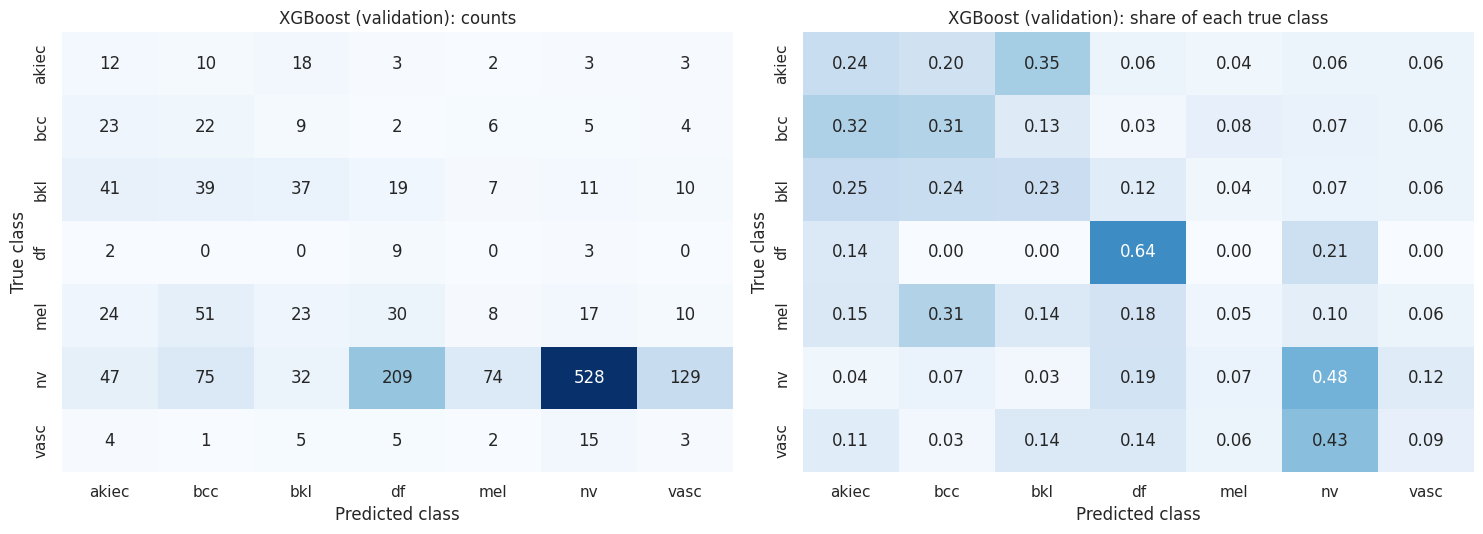

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=SEED,
    n_jobs=-1,
)
xgb_model.fit(X_tab_train, y_train, sample_weight=train_sample_weights)
joblib.dump(xgb_model, TABULAR_DIR / "xgboost.joblib", compress=3)

xgb_val_pred = xgb_model.predict(X_tab_val)
validation_results["XGBoost"] = report_predictions(
    "XGBoost", "validation", y_val, xgb_val_pred,
    save_path=FIGURES_DIR / "confusion_matrix_val_xgboost.png")

### 7.3 Random Forest vs. XGBoost (validation) and choice of the tabular representative
The table is computed from the runs above (nothing is typed in by hand). The model with the higher **validation macro-F1** becomes the "Tabular-only" entry in the final comparison. The test set plays no role in this choice.

,Accuracy,Macro F1,Weighted F1
Random Forest,0.4353,0.2014,0.516
XGBoost,0.3888,0.1889,0.478


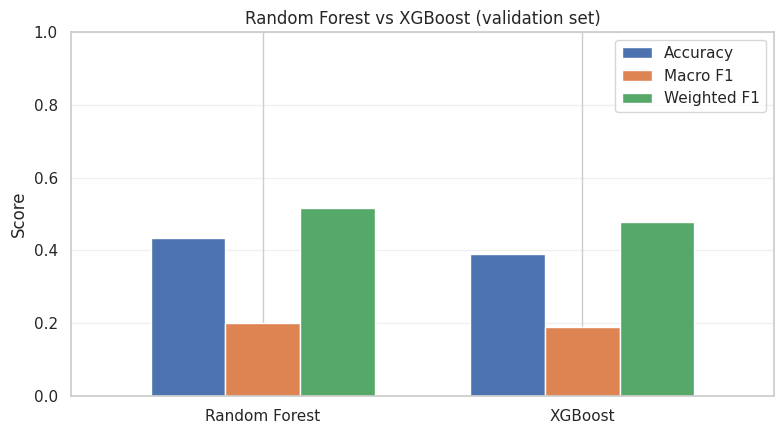

Tabular model selected on validation macro-F1: Random Forest


In [ ]:
tabular_validation_table = pd.DataFrame(
    {name: validation_results[name] for name in ["Random Forest", "XGBoost"]}
).T.rename(columns={"accuracy": "Accuracy", "macro_f1": "Macro F1", "weighted_f1": "Weighted F1"})
display(tabular_validation_table)

tabular_validation_table.plot(kind="bar", figsize=(8, 4.5), ylim=(0, 1), width=0.7)
plt.title("Random Forest vs XGBoost (validation set)")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

best_tabular_name = tabular_validation_table["Macro F1"].idxmax()
print(f"Tabular model selected on validation macro-F1: {best_tabular_name}")

---
## 8. Image-only experiment: custom CNN from scratch

The image model is a small convolutional network that is **trained from random initialisation** on HAM10000 only. No pretrained network of any kind is used. The design choices (kept deliberately simple):

| Component | Choice | Reason |
|---|---|---|
| Input | `128 x 128 x 3` images stored as `uint8`, scaled to `[0, 1]` by the first layer of the model | same preprocessing for training, validation and test, for the CNN and the multimodal model |
| Architecture | 4 blocks of *(Conv-BatchNorm-ReLU) x 2 + MaxPool + Dropout* with 32, 64, 128, 256 filters, then Global Average Pooling and a small dense head | enough capacity for 128 px lesions, few parameters, easy to explain |
| Data augmentation | random flips, rotation and zoom (active during training only) | lesions have no "correct" orientation; augmentation reduces over-fitting |
| Regularisation | Batch Normalisation, Dropout, L2 weight decay, global average pooling | small dataset → over-fitting risk |
| Class imbalance | balanced class weights (Section 6.3) as per-sample weights | rare classes count as much as `nv` |
| Early stopping | stops when validation macro-F1 has not improved for 12 epochs and restores the best weights | avoids over-training |
| LR scheduling | learning rate halves when validation macro-F1 plateaus for 5 epochs | finer convergence |
| Checkpointing | the best epoch (highest validation macro-F1) is saved automatically to `best_model.keras` | the final evaluation reloads this file |

### 8.1 Load and resize all images once
Images are resized to `IMG_SIZE x IMG_SIZE` and kept in memory as `uint8` (about 0.5 GB). They are cached on the local disk so a re-run of the cell is fast. Resizing squashes the original 4:3 images to a square; this is applied identically to all images and all models.

In [ ]:
def load_resized_image(image_path):
    with Image.open(image_path) as image:
        resized = image.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.Resampling.BILINEAR)
        return np.asarray(resized, dtype=np.uint8)


image_cache_file = CACHE_DIR / f"ham10000_images_{IMG_SIZE}px.npy"
X_img_all = None
if image_cache_file.exists():
    cached_images = np.load(image_cache_file)
    if cached_images.shape == (len(df), IMG_SIZE, IMG_SIZE, 3):
        X_img_all = cached_images
        print("Loaded resized images from cache.")

if X_img_all is None:
    with ThreadPoolExecutor(max_workers=4) as pool:
        X_img_all = np.stack(list(tqdm(pool.map(load_resized_image, df["image_path"]), total=len(df))))
    np.save(image_cache_file, X_img_all)

print("All images:", X_img_all.shape, X_img_all.dtype,
      f"| pixel range {X_img_all.min()}-{X_img_all.max()} | {X_img_all.nbytes / 1e6:.0f} MB")

# Row i of X_img_all belongs to row i of df, so the split indices select the images directly.
X_img_train = X_img_all[train_idx]
X_img_val = X_img_all[val_idx]
print("Train images:", X_img_train.shape, "| Validation images:", X_img_val.shape)

  0%|          | 0/10015 [00:00<?, ?it/s]

All images: (10015, 128, 128, 3) uint8 | pixel range 0-255 | 492 MB
Train images: (6409, 128, 128, 3) | Validation images: (1592, 128, 128, 3)


### 8.2 Data augmentation
Augmentation is part of the model (Keras preprocessing layers). These layers are **only active during training** and automatically switched off for validation, test and prediction, so no separate augmentation pipeline is needed. The cell below shows one training image and several random augmentations of it, as a visual sanity check.

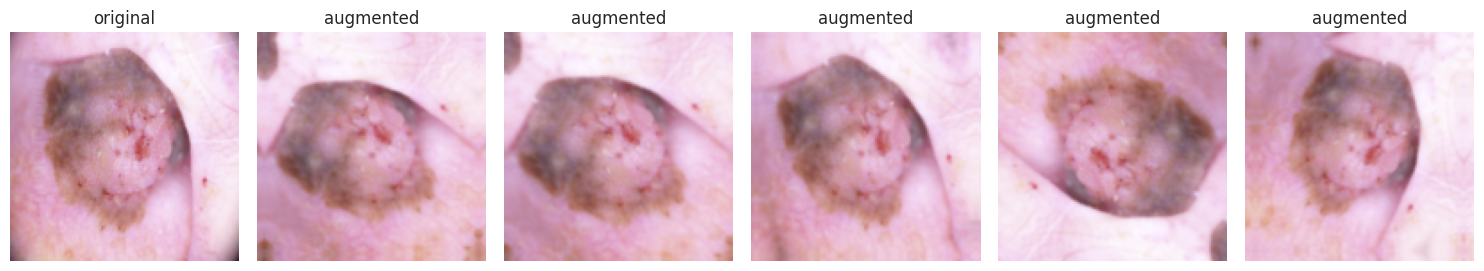

In [ ]:
def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.15, fill_mode="reflect"),
        layers.RandomZoom(0.1, fill_mode="reflect"),
    ], name="augmentation")


demo_image = X_img_train[:1].astype("float32") / 255.0
demo_augmentation = make_augmentation()
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
axes[0].imshow(demo_image[0]); axes[0].set_title("original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(np.clip(demo_augmentation(demo_image, training=True)[0], 0, 1))
    ax.set_title("augmented"); ax.axis("off")
plt.tight_layout()
plt.show()

### 8.3 Reusable training utilities
These functions are shared by the image-only and the multimodal experiment so both are trained with **exactly the same recipe**:

* `make_dataset` / `make_inputs_dataset`: build `tf.data` pipelines (training data is shuffled and carries per-sample class weights).
* `ValidationMacroF1`: after every epoch it computes the **validation macro-F1** and adds it to the training log, so early stopping, LR scheduling and checkpointing can all monitor it.
* `train_model`: compiles, trains with callbacks, and saves the **training history** (`training_history.csv`) and the **configuration** (`training_config.json`) into the experiment's own folder next to `best_model.keras`.
* `plot_learning_curves`, `predict_from_checkpoint`: inspect training and re-load the saved best model for evaluation.

In [ ]:
def make_dataset(inputs, labels, sample_weights=None, shuffle=False):
    # inputs can be one array (CNN) or a dict of arrays (multimodal).
    tensors = (inputs, labels) if sample_weights is None else (inputs, labels, sample_weights)
    dataset = tf.data.Dataset.from_tensor_slices(tensors)
    if shuffle:
        dataset = dataset.shuffle(len(labels), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def make_inputs_dataset(inputs):
    # Inputs only (no labels, never shuffled): used for predictions, keeps the original row order.
    return tf.data.Dataset.from_tensor_slices(inputs).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


class ValidationMacroF1(keras.callbacks.Callback):
    # Computes macro-F1 on the validation set after every epoch and adds it to the training logs.
    def __init__(self, val_inputs_ds, val_labels):
        super().__init__()
        self.val_inputs_ds = val_inputs_ds
        self.val_labels = val_labels
        self.scores = []

    def on_epoch_end(self, epoch, logs=None):
        probabilities = self.model.predict(self.val_inputs_ds, verbose=0)
        score = float(f1_score(self.val_labels, probabilities.argmax(axis=1),
                               average="macro", labels=np.arange(NUM_CLASSES), zero_division=0))
        self.scores.append(score)
        if logs is not None:
            logs["val_macro_f1"] = score


def train_model(keras_model, experiment_dir, config, train_ds, val_ds, val_inputs_ds, val_labels):
    experiment_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = experiment_dir / "best_model.keras"

    keras_model.compile(optimizer=keras.optimizers.Adam(learning_rate=config["learning_rate"]),
                        loss="sparse_categorical_crossentropy",
                        metrics=["accuracy"])

    f1_callback = ValidationMacroF1(val_inputs_ds, val_labels)   # must come first in the list
    callbacks = [
        f1_callback,
        keras.callbacks.ModelCheckpoint(str(checkpoint_path), monitor="val_macro_f1", mode="max",
                                        save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_macro_f1", mode="max",
                                      patience=config["early_stopping_patience"],
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_macro_f1", mode="max",
                                          factor=config["reduce_lr_factor"],
                                          patience=config["reduce_lr_patience"],
                                          min_lr=1e-6, verbose=1),
    ]

    start_time = time.time()
    fit_history = keras_model.fit(train_ds, validation_data=val_ds, epochs=config["max_epochs"],
                                  callbacks=callbacks, verbose=2)
    training_seconds = time.time() - start_time

    history_df = pd.DataFrame(fit_history.history)
    if "val_macro_f1" not in history_df.columns:       # safety net for other Keras versions
        history_df["val_macro_f1"] = f1_callback.scores
    history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
    history_df.to_csv(experiment_dir / "training_history.csv", index=False)

    best_row = history_df["val_macro_f1"].idxmax()
    run_record = dict(config)
    run_record.update({
        "best_epoch": int(history_df.loc[best_row, "epoch"]),
        "best_val_macro_f1": float(history_df.loc[best_row, "val_macro_f1"]),
        "epochs_run": int(len(history_df)),
        "training_seconds": round(training_seconds, 1),
        "tensorflow_version": tf.__version__,
        "seed": SEED,
        "class_names": CLASS_NAMES,
        "class_weights": class_weight_by_idx,
        "n_train": int(len(y_train)),
        "n_validation": int(len(y_val)),
        "checkpoint": str(checkpoint_path),
    })
    with open(experiment_dir / "training_config.json", "w") as config_file:
        json.dump(run_record, config_file, indent=2, default=str)

    print(f"\nBest epoch: {run_record['best_epoch']} "
          f"(validation macro-F1 = {run_record['best_val_macro_f1']:.4f}) | "
          f"{run_record['epochs_run']} epochs in {training_seconds / 60:.1f} min")
    print("Saved:", checkpoint_path.name, "| training_history.csv | training_config.json in", experiment_dir)
    return history_df


def plot_learning_curves(history_df, title, save_path=None):
    best_epoch = int(history_df.loc[history_df["val_macro_f1"].idxmax(), "epoch"])
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    axes[0].plot(history_df["epoch"], history_df["loss"], label="train")
    axes[0].plot(history_df["epoch"], history_df["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[1].plot(history_df["epoch"], history_df["accuracy"], label="train")
    axes[1].plot(history_df["epoch"], history_df["val_accuracy"], label="validation")
    axes[1].set_title("Accuracy")
    axes[2].plot(history_df["epoch"], history_df["val_macro_f1"], color="tab:green", label="validation macro-F1")
    axes[2].set_title("Validation macro-F1 (selection metric)")
    for ax in axes:
        ax.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(title)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def predict_from_checkpoint(checkpoint_path, inputs_ds):
    # Re-load the saved best model from disk and return class probabilities.
    loaded_model = keras.models.load_model(checkpoint_path, compile=False)
    return loaded_model.predict(inputs_ds, verbose=0)

### 8.4 CNN architecture
`image_feature_extractor` (rescaling → augmentation → 4 convolutional blocks → global average pooling) is the **custom, from-scratch image feature extractor**. The image-only model adds a dense classifier on top of it; the multimodal model (Section 9) re-uses exactly the same extractor.

In [ ]:
CNN_CONFIG = {
    "experiment_name": "cnn_scratch",
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "learning_rate": 1e-3,
    "optimizer": "Adam",
    "filters": [32, 64, 128, 256],
    "conv_dropout": 0.2,
    "dense_units": 128,
    "dense_dropout": 0.5,
    "l2_weight": 1e-4,
    "augmentation": "flip(h+v), rotation(0.15), zoom(0.1)",
    "class_imbalance": "balanced class weights as sample weights",
    "monitor": "val_macro_f1",
    "early_stopping_patience": 12,
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 5,
}


def conv_block(x, filters, dropout_rate, l2_weight):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False,
                          kernel_regularizer=keras.regularizers.l2(l2_weight))(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D(2)(x)
    return layers.Dropout(dropout_rate)(x)


def image_feature_extractor(image_input, config):
    # Custom from-scratch feature extractor shared by the CNN and the multimodal model.
    x = layers.Rescaling(1.0 / 255)(image_input)      # uint8 0-255 -> float 0-1 (same for every split)
    x = make_augmentation()(x)                         # only active while training
    for filters in config["filters"]:
        x = conv_block(x, filters, config["conv_dropout"], config["l2_weight"])
    return layers.GlobalAveragePooling2D()(x)


def image_dense_head(features, config):
    x = layers.Dense(config["dense_units"], activation="relu",
                     kernel_regularizer=keras.regularizers.l2(config["l2_weight"]))(features)
    return layers.Dropout(config["dense_dropout"])(x)


def build_cnn_classifier(config):
    image_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    features = image_feature_extractor(image_input, config)
    head = image_dense_head(features, config)
    class_probabilities = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(head)
    return keras.Model(image_input, class_probabilities, name="cnn_from_scratch")


cnn_model = build_cnn_classifier(CNN_CONFIG)
cnn_model.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,935 (4.61 MB)

 Trainable params: 1,207,015 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

### 8.5 Train the CNN
Training data is shuffled and carries the class weights. The validation data is passed without weights, so validation loss and accuracy are the usual unweighted numbers; the checkpoint is selected by validation macro-F1.

Expected duration on a T4 GPU: roughly a few seconds to well under a minute per epoch, at most `MAX_EPOCHS` epochs, usually fewer thanks to early stopping.

In [ ]:
CNN_CHECKPOINT = CNN_DIR / "best_model.keras"

cnn_train_ds = make_dataset(X_img_train, y_train, train_sample_weights, shuffle=True)
cnn_val_ds = make_dataset(X_img_val, y_val)
cnn_val_inputs_ds = make_inputs_dataset(X_img_val)

if FORCE_RETRAIN or not CNN_CHECKPOINT.exists():
    cnn_history_df = train_model(cnn_model, CNN_DIR, CNN_CONFIG,
                                 cnn_train_ds, cnn_val_ds, cnn_val_inputs_ds, y_val)
else:
    print("Found an existing checkpoint, skipping training (set FORCE_RETRAIN = True to retrain).")
    cnn_history_df = pd.read_csv(CNN_DIR / "training_history.csv")

Epoch 1/60

Epoch 1: val_macro_f1 improved from None to 0.00250, saving model to /content/drive/MyDrive/HAM10000_project/cnn_scratch/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HAM10000_project/cnn_scratch/best_model.keras
201/201 - 38s - 189ms/step - accuracy: 0.3901 - loss: 1.8747 - val_accuracy: 0.0088 - val_loss: 2.8771 - val_macro_f1: 0.0025 - learning_rate: 0.0010
Epoch 2/60

Epoch 2: val_macro_f1 improved from 0.00250 to 0.10315, saving model to /content/drive/MyDrive/HAM10000_project/cnn_scratch/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/HAM10000_project/cnn_scratch/best_model.keras
201/201 - 21s - 105ms/step - accuracy: 0.3831 - loss: 1.8221 - val_accuracy: 0.1903 - val_loss: 2.2905 - val_macro_f1: 0.1031 - learning_rate: 0.0010
Epoch 3/60

Epoch 3: val_macro_f1 did not improve from 0.10315
201/201 - 21s - 105ms/step - accuracy: 0.3316 - loss: 1.7748 - val_accuracy: 0.0440 - val_loss: 2.3304 - val_macro_f1: 0.0484 

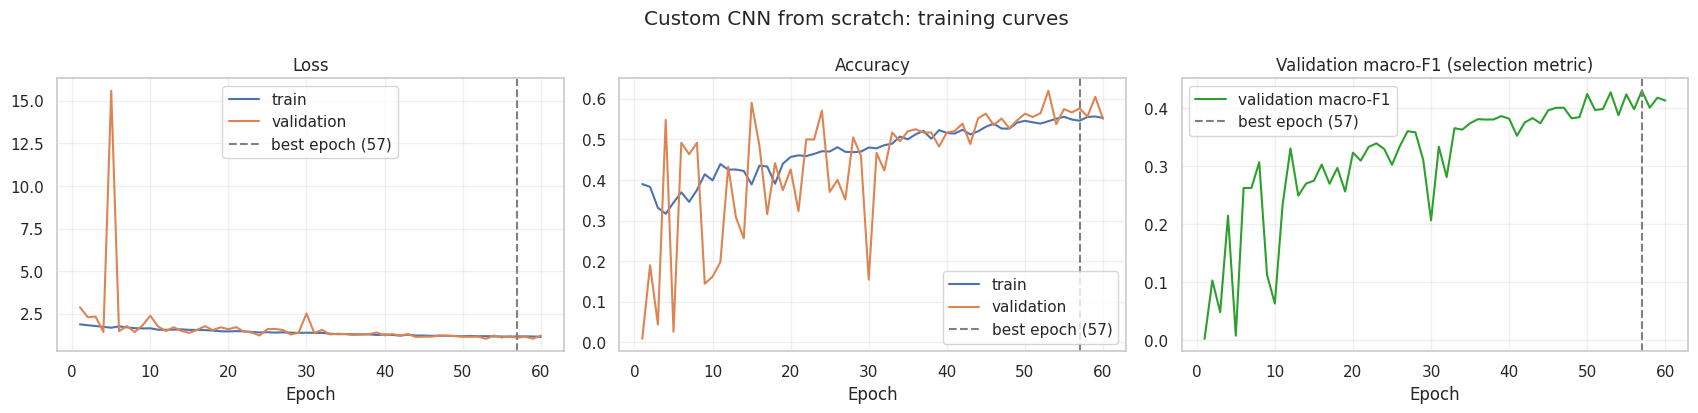

In [ ]:
plot_learning_curves(cnn_history_df, "Custom CNN from scratch: training curves",
                     save_path=FIGURES_DIR / "learning_curves_cnn.png")

### 8.6 Evaluate the saved best checkpoint (validation set)
The model is re-loaded **from the saved file** (not taken from memory), which proves that the checkpoint works on its own. Look at the confusion matrix: a good model does not simply predict `nv` for everything.

Custom CNN (from scratch)  |  validation set
------------------------------------------------------------
Accuracy    : 0.5766
Macro F1    : 0.4299
Weighted F1 : 0.6336

              precision    recall  f1-score   support

       akiec      0.202     0.667     0.311        51
         bcc      0.451     0.324     0.377        71
         bkl      0.419     0.488     0.451       164
          df      0.090     0.500     0.152        14
         mel      0.248     0.613     0.353       163
          nv      0.975     0.598     0.741      1094
        vasc      0.690     0.571     0.625        35

    accuracy                          0.577      1592
   macro avg      0.439     0.537     0.430      1592
weighted avg      0.781     0.577     0.634      1592



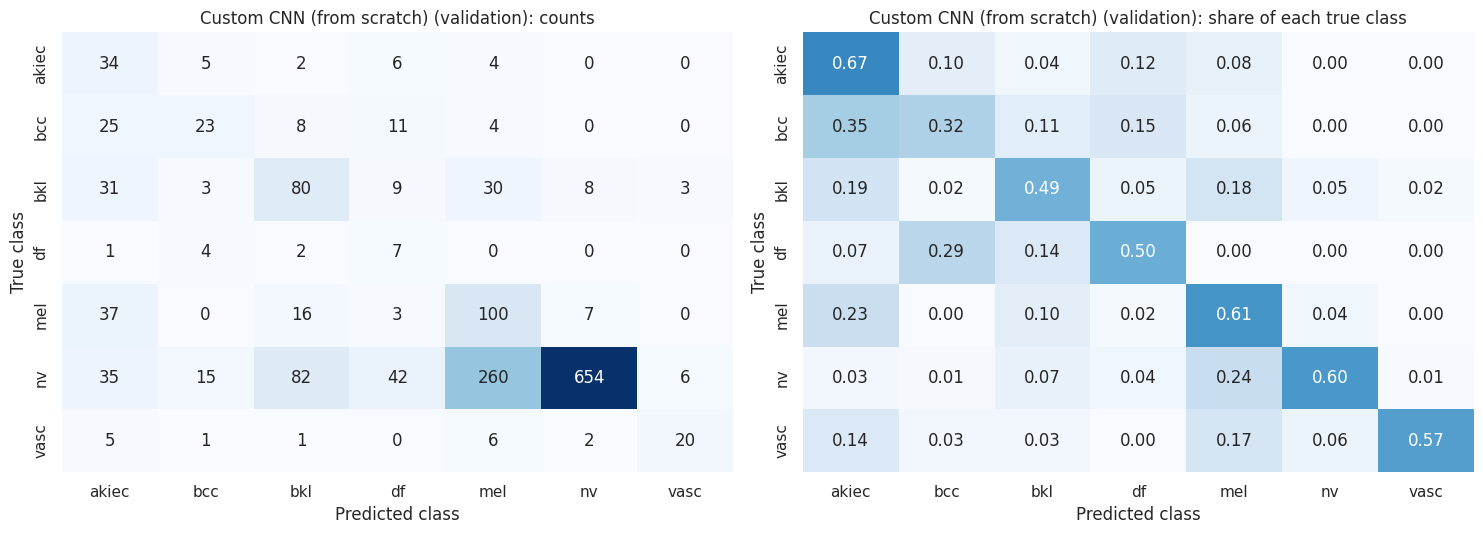

In [ ]:
IMAGE_MODEL_NAME = "Custom CNN (from scratch)"

cnn_val_probabilities = predict_from_checkpoint(CNN_CHECKPOINT, make_inputs_dataset(X_img_val))
cnn_val_pred = cnn_val_probabilities.argmax(axis=1)
validation_results[IMAGE_MODEL_NAME] = report_predictions(
    IMAGE_MODEL_NAME, "validation", y_val, cnn_val_pred,
    save_path=FIGURES_DIR / "confusion_matrix_val_cnn.png")

---
## 9. Multimodal experiment: custom CNN + tabular features

The multimodal network has **two branches** whose outputs are concatenated:

* **Image branch**: the *same* from-scratch feature extractor and dense layer as the image-only CNN (no pretrained model).
* **Tabular branch**: a small dense layer on the preprocessed `age`, `sex`, `localization` vector (the same matrix used by the tabular models).
* **Fusion head**: concatenation → dense layer with dropout → softmax over the 7 classes. The whole network is trained **end to end** with the same recipe as the CNN: same augmentation, class weights, optimiser, early stopping, LR scheduling and checkpoint rule. The only difference between the image-only and the multimodal experiment is therefore the extra tabular information.

In [ ]:
MULTIMODAL_CONFIG = dict(CNN_CONFIG)
MULTIMODAL_CONFIG.update({
    "experiment_name": "multimodal_scratch",
    "tabular_hidden_units": 32,
    "tabular_dropout": 0.2,
    "fusion_units": 64,
    "fusion_dropout": 0.4,
    "n_tabular_features": int(X_tab_train.shape[1]),
})


def build_multimodal_classifier(config):
    image_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    tabular_input = keras.Input(shape=(config["n_tabular_features"],), name="tabular")

    # Image branch: custom CNN feature extractor (identical to the image-only model)
    image_features = image_dense_head(image_feature_extractor(image_input, config), config)

    # Tabular branch
    tabular_features = layers.Dense(config["tabular_hidden_units"], activation="relu")(tabular_input)
    tabular_features = layers.Dropout(config["tabular_dropout"])(tabular_features)

    # Fusion
    fused = layers.Concatenate()([image_features, tabular_features])
    fused = layers.Dense(config["fusion_units"], activation="relu",
                         kernel_regularizer=keras.regularizers.l2(config["l2_weight"]))(fused)
    fused = layers.Dropout(config["fusion_dropout"])(fused)
    class_probabilities = layers.Dense(NUM_CLASSES, activation="softmax", name="class_probabilities")(fused)

    return keras.Model(inputs={"image": image_input, "tabular": tabular_input},
                       outputs=class_probabilities, name="multimodal_from_scratch")


multimodal_model = build_multimodal_classifier(MULTIMODAL_CONFIG)
multimodal_model.summary()

Model: "multimodal_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 128, 128,  │          0 │ image[0][0]       │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ augmentation        │ (None, 128, 128,  │          0 │ rescaling_1[0][0] │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │        864 │ augmentation[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_8 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      9,216 │ re_lu_8[0][0]     │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_9 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 64, 64,    │          0 │ re_lu_9[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │     18,432 │ dropout_5[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_10 (ReLU)     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │     36,864 │ re_lu_10[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_11 (ReLU)     │ (None, 64, 64,    │          0 │ batch_normalizat

 Total params: 1,219,431 (4.65 MB)

 Trainable params: 1,217,511 (4.64 MB)

 Non-trainable params: 1,920 (7.50 KB)

### 9.1 Train the multimodal model

In [ ]:
MULTIMODAL_CHECKPOINT = MULTIMODAL_DIR / "best_model.keras"
MULTIMODAL_MODEL_NAME = "Multimodal (CNN + tabular)"

multimodal_train_inputs = {"image": X_img_train, "tabular": X_tab_train}
multimodal_val_inputs = {"image": X_img_val, "tabular": X_tab_val}

multimodal_train_ds = make_dataset(multimodal_train_inputs, y_train, train_sample_weights, shuffle=True)
multimodal_val_ds = make_dataset(multimodal_val_inputs, y_val)
multimodal_val_inputs_ds = make_inputs_dataset(multimodal_val_inputs)

if FORCE_RETRAIN or not MULTIMODAL_CHECKPOINT.exists():
    multimodal_history_df = train_model(multimodal_model, MULTIMODAL_DIR, MULTIMODAL_CONFIG,
                                        multimodal_train_ds, multimodal_val_ds,
                                        multimodal_val_inputs_ds, y_val)
else:
    print("Found an existing checkpoint, skipping training (set FORCE_RETRAIN = True to retrain).")
    multimodal_history_df = pd.read_csv(MULTIMODAL_DIR / "training_history.csv")

Epoch 1/60

Epoch 1: val_macro_f1 improved from None to 0.04358, saving model to /content/drive/MyDrive/HAM10000_project/multimodal_scratch/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/HAM10000_project/multimodal_scratch/best_model.keras
201/201 - 30s - 149ms/step - accuracy: 0.3359 - loss: 1.9698 - val_accuracy: 0.0371 - val_loss: 2.4788 - val_macro_f1: 0.0436 - learning_rate: 0.0010
Epoch 2/60

Epoch 2: val_macro_f1 improved from 0.04358 to 0.09693, saving model to /content/drive/MyDrive/HAM10000_project/multimodal_scratch/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/HAM10000_project/multimodal_scratch/best_model.keras
201/201 - 22s - 112ms/step - accuracy: 0.4188 - loss: 1.8089 - val_accuracy: 0.1325 - val_loss: 2.2686 - val_macro_f1: 0.0969 - learning_rate: 0.0010
Epoch 3/60

Epoch 3: val_macro_f1 improved from 0.09693 to 0.30810, saving model to /content/drive/MyDrive/HAM10000_project/multimodal_scratch/best_model.keras



In [ ]:
plot_learning_curves(multimodal_history_df, "Multimodal model: training curves",
                     save_path=FIGURES_DIR / "learning_curves_multimodal.png")

### 9.2 Evaluate the saved best checkpoint (validation set)

In [ ]:
multimodal_val_probabilities = predict_from_checkpoint(MULTIMODAL_CHECKPOINT, make_inputs_dataset(multimodal_val_inputs))
multimodal_val_pred = multimodal_val_probabilities.argmax(axis=1)
validation_results[MULTIMODAL_MODEL_NAME] = report_predictions(
    MULTIMODAL_MODEL_NAME, "validation", y_val, multimodal_val_pred,
    save_path=FIGURES_DIR / "confusion_matrix_val_multimodal.png")

### 9.3 Validation summary of all experiments
These are **validation** numbers (used for development decisions). The unbiased comparison on the untouched test set follows in Section 10.

In [ ]:
validation_summary = pd.DataFrame(validation_results).T.rename(
    columns={"accuracy": "Accuracy", "macro_f1": "Macro F1", "weighted_f1": "Weighted F1"})
display(validation_summary)
validation_summary.to_csv(RESULTS_DIR / "validation_metrics.csv")

---
## 10. Final evaluation and comparison of all three approaches

**This is the first and only place where the test set is used.** All modelling decisions were already made on the validation set, and nothing below changes any model.

### 10.1 Prepare the test data and load every saved model
* The tabular preprocessing object **fitted on the training set** is applied to the test features (`transform`, never `fit`).
* The tabular models are re-loaded from `joblib` files; the CNN and the multimodal model are re-loaded from their saved `best_model.keras` checkpoints.

In [ ]:
# ---- test data (first use of the test set) ----
y_test = df["label"].to_numpy()[test_idx]
X_img_test = X_img_all[test_idx]
X_tab_test = tabular_preprocessor.transform(test_df[TABULAR_FEATURES]).astype("float32")
print("Test images:", X_img_test.shape, "| test tabular:", X_tab_test.shape, "| test labels:", y_test.shape)

# ---- predictions of every saved model ----
test_predictions = {}

for model_name, model_file in [("Random Forest", "random_forest.joblib"), ("XGBoost", "xgboost.joblib")]:
    loaded_tabular_model = joblib.load(TABULAR_DIR / model_file)
    test_predictions[model_name] = loaded_tabular_model.predict(X_tab_test)

test_predictions[IMAGE_MODEL_NAME] = predict_from_checkpoint(
    CNN_CHECKPOINT, make_inputs_dataset(X_img_test)).argmax(axis=1)

test_predictions[MULTIMODAL_MODEL_NAME] = predict_from_checkpoint(
    MULTIMODAL_CHECKPOINT, make_inputs_dataset({"image": X_img_test, "tabular": X_tab_test})).argmax(axis=1)

# The three approaches that are compared (tabular = the model chosen on VALIDATION macro-F1).
APPROACH_TO_MODEL = {
    "Tabular-only": best_tabular_name,
    "Image-only": IMAGE_MODEL_NAME,
    "Multimodal": MULTIMODAL_MODEL_NAME,
}
print("\nModel used for each approach:", APPROACH_TO_MODEL)

### 10.2 Detailed test results of the three approaches
Accuracy, macro-F1, weighted-F1, classification report and confusion matrix for each approach.

In [ ]:
test_results = {}
for approach, model_name in APPROACH_TO_MODEL.items():
    print("=" * 70)
    print(f"APPROACH: {approach}")
    print("=" * 70)
    safe_name = approach.lower().replace("-", "_")
    test_results[approach] = report_predictions(
        model_name, "test", y_test, test_predictions[model_name],
        save_path=FIGURES_DIR / f"confusion_matrix_test_{safe_name}.png")

### 10.3 Final comparison table and chart
Every value comes from the predictions above. The second table also lists both tabular models, for completeness.

In [ ]:
final_table = pd.DataFrame(test_results).T.rename(
    columns={"accuracy": "Accuracy", "macro_f1": "Macro F1", "weighted_f1": "Weighted F1"})
final_table.insert(0, "Model", [APPROACH_TO_MODEL[a] for a in final_table.index])
final_table.index.name = "Approach"
print("TEST SET: comparison of the three approaches")
display(final_table)
final_table.to_csv(RESULTS_DIR / "final_comparison_test.csv")

all_models_test_table = pd.DataFrame(
    {name: compute_metrics(y_test, pred) for name, pred in test_predictions.items()}
).T.rename(columns={"accuracy": "Accuracy", "macro_f1": "Macro F1", "weighted_f1": "Weighted F1"})
print("TEST SET: all trained models")
display(all_models_test_table)
all_models_test_table.to_csv(RESULTS_DIR / "all_models_test_metrics.csv")

# ---- grouped bar chart ----
metric_columns = ["Accuracy", "Macro F1", "Weighted F1"]
fig, ax = plt.subplots(figsize=(9, 5))
bar_width = 0.25
for position, approach in enumerate(final_table.index):
    bars = ax.bar(np.arange(len(metric_columns)) + (position - 1) * bar_width,
                  final_table.loc[approach, metric_columns].astype(float).values,
                  width=bar_width, label=approach)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(np.arange(len(metric_columns)))
ax.set_xticklabels(metric_columns)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("HAM10000 test set: Tabular-only vs Image-only vs Multimodal")
ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "final_comparison_test.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.4 Per-class F1 on the test set
Macro-F1 is an average; this view shows **which classes** each approach handles well or badly (important for rare but clinically relevant classes such as `mel`).

In [ ]:
per_class_f1 = pd.DataFrame({
    approach: f1_score(y_test, test_predictions[model_name], labels=np.arange(NUM_CLASSES),
                       average=None, zero_division=0)
    for approach, model_name in APPROACH_TO_MODEL.items()
}, index=CLASS_NAMES)
per_class_f1.index.name = "Class"
display(per_class_f1)
per_class_f1.to_csv(RESULTS_DIR / "per_class_f1_test.csv")

plt.figure(figsize=(7.5, 5))
sns.heatmap(per_class_f1, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Per-class F1 on the test set")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "per_class_f1_test.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.5 How certain are the differences? (bootstrap confidence intervals)
The test set is finite, so every score has some random uncertainty. We estimate a **95 % confidence interval for macro-F1** by repeatedly re-sampling the test set. Because several images can belong to the same lesion, we re-sample **whole lesions** (not single images). All three approaches are scored on the same re-samples. If two intervals overlap strongly, the data do not show a clear difference between those approaches.

In [ ]:
def lesion_bootstrap_macro_f1_ci(y_true, predictions_by_name, lesion_ids, n_boot, seed=SEED):
    rng = np.random.default_rng(seed)
    codes, _ = pd.factorize(lesion_ids)
    order = np.argsort(codes, kind="stable")
    rows_by_lesion = np.split(order, np.cumsum(np.bincount(codes))[:-1])   # list: lesion -> row positions
    n_lesions = len(rows_by_lesion)

    scores = {name: [] for name in predictions_by_name}
    for _ in range(n_boot):
        chosen = rng.integers(0, n_lesions, n_lesions)                      # sample lesions with replacement
        rows = np.concatenate([rows_by_lesion[i] for i in chosen])
        for name, prediction in predictions_by_name.items():
            scores[name].append(f1_score(y_true[rows], prediction[rows], average="macro",
                                         labels=np.arange(NUM_CLASSES), zero_division=0))
    return {name: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for name, v in scores.items()}


approach_predictions = {approach: test_predictions[model_name] for approach, model_name in APPROACH_TO_MODEL.items()}
macro_f1_ci = lesion_bootstrap_macro_f1_ci(y_test, approach_predictions,
                                            test_df["lesion_id"].to_numpy(), n_boot=N_BOOTSTRAP)

ci_table = final_table[["Model", "Macro F1"]].copy()
ci_table["95% CI low"] = [macro_f1_ci[a][0] for a in ci_table.index]
ci_table["95% CI high"] = [macro_f1_ci[a][1] for a in ci_table.index]
print(f"Macro-F1 with 95% lesion-level bootstrap CI ({N_BOOTSTRAP} resamples)")
display(ci_table)
ci_table.to_csv(RESULTS_DIR / "macro_f1_confidence_intervals.csv")

### 10.6 Validation vs. test
A large drop from validation to test would indicate that model selection over-fitted the validation set. (Both columns are real measurements from this run.)

In [ ]:
val_vs_test = pd.DataFrame({
    "Model": [APPROACH_TO_MODEL[a] for a in final_table.index],
    "Val Macro F1": [validation_results[APPROACH_TO_MODEL[a]]["macro_f1"] for a in final_table.index],
    "Test Macro F1": final_table["Macro F1"].astype(float).values,
    "Val Accuracy": [validation_results[APPROACH_TO_MODEL[a]]["accuracy"] for a in final_table.index],
    "Test Accuracy": final_table["Accuracy"].astype(float).values,
}, index=final_table.index)
display(val_vs_test)

---
## 11. Conclusions and limitations

### 11.1 Results of this run (generated automatically)
The statements printed below are computed from the test results of the run you just executed, so they always match the tables above.

In [ ]:
macro_f1_by_approach = final_table["Macro F1"].astype(float)
accuracy_by_approach = final_table["Accuracy"].astype(float)

print(f"Highest test macro-F1 : {macro_f1_by_approach.idxmax()} ({macro_f1_by_approach.max():.4f})")
print(f"Highest test accuracy : {accuracy_by_approach.idxmax()} ({accuracy_by_approach.max():.4f})")
print()

for approach_a, approach_b in [("Multimodal", "Image-only"),
                               ("Multimodal", "Tabular-only"),
                               ("Image-only", "Tabular-only")]:
    difference = macro_f1_by_approach[approach_a] - macro_f1_by_approach[approach_b]
    low_a, high_a = macro_f1_ci[approach_a]
    low_b, high_b = macro_f1_ci[approach_b]
    overlap = not (high_a < low_b or high_b < low_a)
    print(f"Macro-F1 {approach_a} - {approach_b}: {difference:+.4f}  "
          f"(95% CIs {'overlap' if overlap else 'do not overlap'})")

print("\nWeakest class per approach (lowest test F1):")
for approach in per_class_f1.columns:
    print(f"  {approach:13s}: {per_class_f1[approach].idxmin()} (F1 = {per_class_f1[approach].min():.3f})")

### 11.2 How to interpret the comparison
* **Macro-F1 is the headline metric.** HAM10000 is dominated by `nv`, so accuracy can look good even when rare classes are mostly missed. Always read accuracy together with macro-F1 and the per-class table.
* **Overlapping confidence intervals** (Section 10.5) mean the experiment cannot separate two approaches; do not claim one is better in that case.
* **What each comparison tells you:** *Tabular-only vs. Image-only* shows how much information the lesion image carries beyond `age`, `sex` and `localization`. *Image-only vs. Multimodal* isolates the benefit of adding the tabular data to the same image network.
* Describe your findings with the numbers from your own run, and mention the random seed and that GPU training can differ slightly between runs.

### 11.3 Limitations
* **One split, one seed.** Results come from a single lesion-grouped split and a single training run per model. Repeating with several seeds or cross-validation would give more reliable estimates.
* **Class imbalance.** Rare classes have few test images, so their per-class scores are noisy.
* **Tabular information is weak.** Only three tabular features are available; low tabular-only performance is expected and is not a coding error.
* **Image resolution.** Images are downsized to 128 x 128 for speed and the 4:3 images are squeezed to a square; fine dermatoscopic detail is lost. Larger images or a deeper network could help but cost more compute.
* **No pretrained models by design.** A from-scratch CNN on about 6,400 training images has limited capacity to generalise; this restriction is a project requirement, not a recommendation for clinical use.
* **Model selection fairness.** The neural networks use augmentation, early stopping and LR scheduling, whereas Random Forest and XGBoost keep their original fixed hyper-parameters (no tuning). A fully tuned tabular baseline could score somewhat higher.
* **Dataset bias.** HAM10000 comes from specific clinics and populations; results may not transfer to other devices, skin types or settings. Image-level labels are used as given.
* **Not a medical device.** Nothing here has been clinically validated.

### 11.4 Saved files
The cell below lists everything written to the project folder.

In [ ]:
print("Project folder:", PROJECT_DIR, "\n")
for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(f"{str(path.relative_to(PROJECT_DIR)):55s} {path.stat().st_size / 1e6:8.2f} MB")

In [4]:
import sys
from pathlib import Path

try:
    import gradio as gr
    import numpy as np
    import pandas as pd
    import joblib
    from PIL import Image
except ModuleNotFoundError:
    !{sys.executable} -m pip install -q gradio numpy pandas joblib pillow
    import gradio as gr
    import numpy as np
    import pandas as pd
    import joblib
    from PIL import Image

try:
    import tensorflow as tf
    TF_AVAILABLE = True
except Exception:
    TF_AVAILABLE = False

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]
LESION_AR = {
    "akiec": "تقران سفعي / سرطانة لابدة (akiec)",
    "bcc": "سرطان الخلايا القاعدية (bcc)",
    "bkl": "تقران حميد (bkl)",
    "df": "ورم ليفي جلدي (df)",
    "mel": "ميلانوما (mel)",
    "nv": "وحمة ميلانينية / شامة (nv)",
    "vasc": "آفات وعائية (vasc)",
}

LOCALIZATIONS = [
    "back", "lower extremity", "trunk", "upper extremity", "abdomen",
    "face", "chest", "foot", "unknown", "neck", "scalp", "hand",
    "ear", "genital", "acral"
]

# محاولة تحميل الموديلات الحقيقية إن وجدت في الجلسة أو المجلدات
def load_available_artifacts():
    artifacts = {
        "preprocessor": globals().get("tabular_preprocessor", None),
        "rf": globals().get("rf_loaded", None),
        "xgb": globals().get("xgb_loaded", None),
        "cnn": globals().get("cnn_loaded", None),
        "multi": globals().get("multi_loaded", None),
        "img_size": int(globals().get("IMG_SIZE", 128)),
    }

    proj_dir = Path(globals().get("PROJECT_DIR", "."))
    tab_dir = Path(globals().get("TABULAR_DIR", proj_dir / "tabular_models"))
    cnn_ckpt = Path(globals().get("CNN_CHECKPOINT", proj_dir / "cnn_scratch" / "best_model.keras"))
    multi_ckpt = Path(globals().get("MULTIMODAL_CHECKPOINT", proj_dir / "multimodal_scratch" / "best_model.keras"))
    prep_file = proj_dir / "tabular_preprocessor.joblib"

    if artifacts["preprocessor"] is None and prep_file.exists():
        try:
            artifacts["preprocessor"] = joblib.load(prep_file)
        except Exception:
            pass

    if artifacts["rf"] is None and (tab_dir / "random_forest.joblib").exists():
        try:
            artifacts["rf"] = joblib.load(tab_dir / "random_forest.joblib")
        except Exception:
            pass

    if artifacts["xgb"] is None and (tab_dir / "xgboost.joblib").exists():
        try:
            artifacts["xgb"] = joblib.load(tab_dir / "xgboost.joblib")
        except Exception:
            pass

    if TF_AVAILABLE:
        if artifacts["cnn"] is None and cnn_ckpt.exists():
            try:
                artifacts["cnn"] = tf.keras.models.load_model(cnn_ckpt, compile=False)
            except Exception:
                pass
        if artifacts["multi"] is None and multi_ckpt.exists():
            try:
                artifacts["multi"] = tf.keras.models.load_model(multi_ckpt, compile=False)
            except Exception:
                pass

    return artifacts

ART = load_available_artifacts()

def demo_probs_from_seed(seed_val):
    rng = np.random.default_rng(int(abs(seed_val)) % (2**31 - 1) + 1)
    raw = rng.dirichlet(np.ones(len(CLASS_NAMES)) * 1.4)
    return np.round(raw * 100, 2)

def prep_image(img, target_size):
    if isinstance(img, np.ndarray):
        pil_img = Image.fromarray(img).convert("RGB")
    else:
        pil_img = img.convert("RGB")
    resized = pil_img.resize((target_size, target_size), Image.Resampling.BILINEAR)
    return np.expand_dims(np.asarray(resized, dtype=np.uint8), axis=0)

def prep_tabular(age, sex, localization):
    df_row = pd.DataFrame([{"age": age, "sex": sex, "localization": localization}])
    if ART["preprocessor"] is not None:
        return ART["preprocessor"].transform(df_row).astype("float32")
    return None

def toggle_inputs(mode):
    show_img = mode in ["الصور فقط (Image-only)", "الدمج (Multimodal)"]
    show_tab = mode in ["البيانات فقط (Tabular-only)", "الدمج (Multimodal)"]
    return (
        gr.update(visible=show_img),
        gr.update(visible=show_tab),
        gr.update(visible=show_tab),
        gr.update(visible=show_tab),
    )

def run_prediction(mode, image, age, sex, localization):
    using_real_model = False
    mode_note = ""

    if mode == "الصور فقط (Image-only)":
        if image is None:
            return "⚠️ من فضلك ارفع صورة أولاً.", pd.DataFrame(), pd.DataFrame()
        X_img = prep_image(image, ART["img_size"])
        if ART["cnn"] is not None:
            probs = ART["cnn"].predict(X_img, verbose=0)[0] * 100
            using_real_model = True
        else:
            probs = demo_probs_from_seed(int(X_img.mean() * 100) + 11)

    elif mode == "البيانات فقط (Tabular-only)":
        X_tab = prep_tabular(age, sex, localization)
        if X_tab is not None and (ART["xgb"] is not None or ART["rf"] is not None):
            model_tab = ART["xgb"] if ART["xgb"] is not None else ART["rf"]
            probs = model_tab.predict_proba(X_tab)[0] * 100
            using_real_model = True
        else:
            seed_num = int(age or 0) * 31 + sum(ord(c) for c in f"{sex}-{localization}")
            probs = demo_probs_from_seed(seed_num)

    else:  # الدمج (Multimodal)
        if image is None:
            return "⚠️ من فضلك ارفع صورة وأدخل البيانات المطلوبة للدمج.", pd.DataFrame(), pd.DataFrame()
        X_img = prep_image(image, ART["img_size"])
        X_tab = prep_tabular(age, sex, localization)
        if ART["multi"] is not None and X_tab is not None:
            probs = ART["multi"].predict({"image": X_img, "tabular": X_tab}, verbose=0)[0] * 100
            using_real_model = True
        else:
            seed_num = int(X_img.mean() * 100) + int(age or 0) * 17 + len(str(localization))
            probs = demo_probs_from_seed(seed_num)

    best_idx = int(np.argmax(probs))
    best_code = CLASS_NAMES[best_idx]
    best_ar = LESION_AR[best_code]
    best_conf = float(probs[best_idx])

    status_badge = "✅ نتيجة من الموديل المحفوظ" if using_real_model else "ℹ️ نتيجة توضيحية (لا توجد موديلات محفوظة في الجلسة بعد)"
    summary_text = (
        f"الوضع المختار: {mode}\n"
        f"{status_badge}\n\n"
        f"التشخيص المرجّح: {best_ar}\n"
        f"نسبة الثقة: {best_conf:.2f}%"
    )

    detail_df = pd.DataFrame({
        "المرض": [LESION_AR[c] for c in CLASS_NAMES],
        "الكود": CLASS_NAMES,
        "نسبة الثقة (%)": np.round(probs, 2),
    }).sort_values("نسبة الثقة (%)", ascending=False).reset_index(drop=True)

    chart_df = pd.DataFrame({
        "الفئة": CLASS_NAMES,
        "الثقة (%)": np.round(probs, 2),
    })

    return summary_text, detail_df, chart_df

with gr.Blocks(title="اختيار الموديل وتشخيص آفات الجلد") as app:
    gr.Markdown("## 🩺 تحديد الموديل وتشخيص آفات الجلد (HAM10000)")
    gr.Markdown("اختر نوع الموديل أولاً، وستظهر لك الحقول المطلوبة فقط لهذا الاختيار.")

    with gr.Row():
        with gr.Column(scale=1):
            model_choice = gr.Radio(
                choices=[
                    "الصور فقط (Image-only)",
                    "البيانات فقط (Tabular-only)",
                    "الدمج (Multimodal)",
                ],
                value="الصور فقط (Image-only)",
                label="1️⃣ اختر الموديل"
            )

            img_input = gr.Image(label="ارفع صورة الآفة الجلدية", visible=True)
            age_input = gr.Number(label="العمر (Age)", value=45, minimum=0, maximum=120, visible=False)
            sex_input = gr.Dropdown(
                choices=["male", "female", "unknown"],
                value="male",
                label="الجنس (Sex)",
                visible=False
            )
            loc_input = gr.Dropdown(
                choices=LOCALIZATIONS,
                value="back",
                label="مكان الإصابة (Localization)",
                visible=False
            )

            submit_btn = gr.Button("🔍 تحديد المرض وعرض النسب", variant="primary")

        with gr.Column(scale=1.3):
            out_summary = gr.Textbox(label="🏆 النتيجة والتشخيص", lines=6)
            out_table = gr.Dataframe(label="📊 نسب الثقة (%) لكل مرض")
            out_chart = gr.BarPlot(x="الفئة", y="الثقة (%)", label="رسم بياني لنسب الثقة")

    model_choice.change(
        fn=toggle_inputs,
        inputs=[model_choice],
        outputs=[img_input, age_input, sex_input, loc_input]
    )

    submit_btn.click(
        fn=run_prediction,
        inputs=[model_choice, img_input, age_input, sex_input, loc_input],
        outputs=[out_summary, out_table, out_chart]
    )

app.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/layouts/column.py:59: UserWarning: 'scale' value should be an integer. Using 1.3 will cause issues.
  warnings.warn(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://1026c48b1e87d69c5a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
